In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.linear_model import LogisticRegression

In [7]:
df = pd.read_csv(r"E:\logistic\network_intrusion_synthetic.csv")

X = df.drop("intrusion", axis=1)
y = df["intrusion"]

X = pd.get_dummies(X, columns=["protocol_type", "service"], drop_first=True)
X = X.astype(float)

print("Features:", X.shape)
print("Target:", y.unique())

Features: (5000, 18)
Target: [0 1]


In [8]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    random_state=42,
    stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (3000, 18)
Validation: (1000, 18)
Test: (1000, 18)


In [9]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

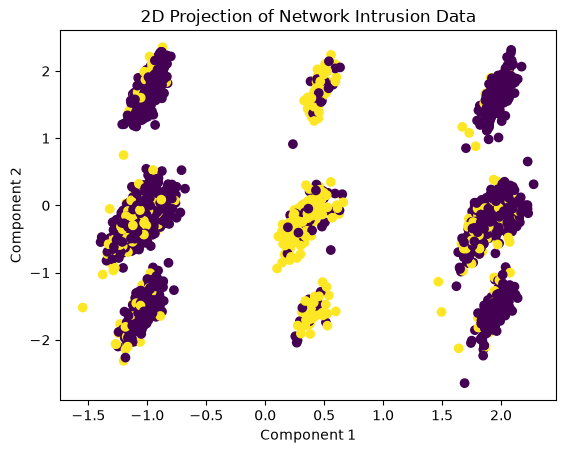

In [10]:
svd = TruncatedSVD(n_components=2, random_state=42)

X_train_2D = svd.fit_transform(X_train)

plt.scatter(X_train_2D[:, 0], X_train_2D[:, 1], c=y_train)
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("2D Projection of Network Intrusion Data")
plt.show()

In [11]:
weights = np.zeros(X_train.shape[1])
bias = 0
learning_rate = 0.01
epochs = 10
misclassifications = []
for epoch in range(epochs):
    errors = 0
    for i in range(len(X_train)):
        z = np.dot(X_train[i], weights) + bias
        prediction = 1 if z >= 0 else 0
        error = y_train.iloc[i] - prediction
        if error != 0:
            weights += learning_rate * error * X_train[i]
            bias += learning_rate * error
            errors += 1
    misclassifications.append(errors)
print("Misclassifications:", misclassifications)


Misclassifications: [530, 533, 514, 526, 519, 512, 521, 508, 525, 513]


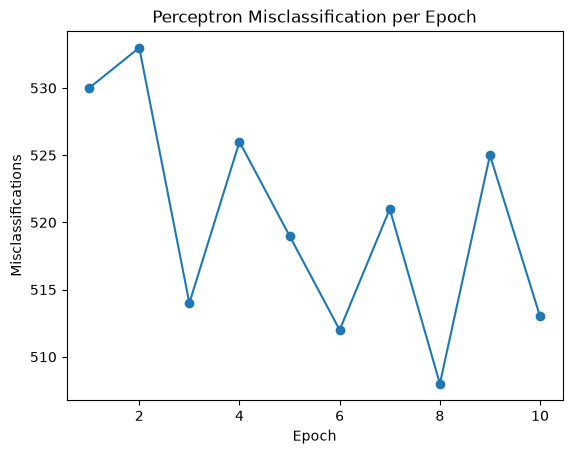

In [12]:
plt.plot(range(1, epochs + 1), misclassifications, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Misclassifications")
plt.title("Perceptron Misclassification per Epoch")
plt.show()

In [13]:
y_pred_perceptron = []
for i in range(len(X_test)):
    z = np.dot(X_test[i], weights) + bias
    prediction = 1 if z >= 0 else 0
    y_pred_perceptron.append(prediction)
print("Perceptron Accuracy:",
      accuracy_score(y_test, y_pred_perceptron))

Perceptron Accuracy: 0.829


In [14]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)
model.fit(X_train, y_train)
y_pred_logistic = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_logistic))

Logistic Regression Accuracy: 0.878


In [15]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))
weights_lr = np.zeros(X_train.shape[1])
bias_lr = 0
learning_rate = 0.01
epochs_lr = 1000

cost_history = []

for epoch in range(epochs_lr):
    z = X_train @ weights_lr + bias_lr
    probability = sigmoid(z)

    error = probability - y_train.values

    dw = (X_train.T @ error) / len(X_train)
    db = np.mean(error)

    weights_lr -= learning_rate * dw
    bias_lr -= learning_rate * db

    cost = -np.mean(
        y_train.values * np.log(np.clip(probability, 1e-15, 1)) +
        (1 - y_train.values) *
        np.log(np.clip(1 - probability, 1e-15, 1))
    )

    cost_history.append(cost)

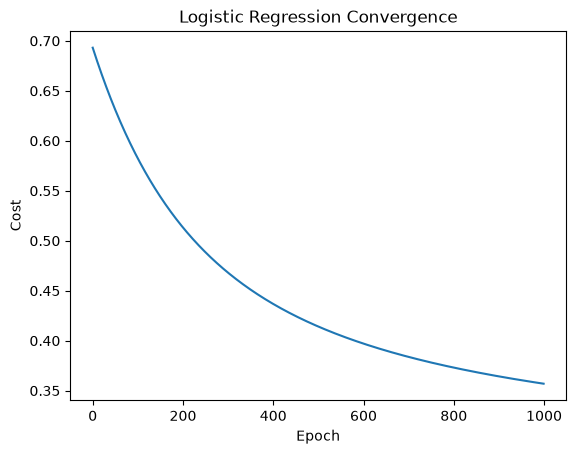

In [16]:
plt.plot(cost_history)
plt.xlabel("Epoch")
plt.ylabel("Cost")
plt.title("Logistic Regression Convergence")
plt.show()

In [17]:
print("Accuracy :", accuracy_score(y_test, y_pred_logistic))
print("Precision:", precision_score(y_test, y_pred_logistic))
print("Recall   :", recall_score(y_test, y_pred_logistic))
print("F1-score :", f1_score(y_test, y_pred_logistic))

Accuracy : 0.878
Precision: 0.7692307692307693
Recall   : 0.6363636363636364
F1-score : 0.6965174129353234


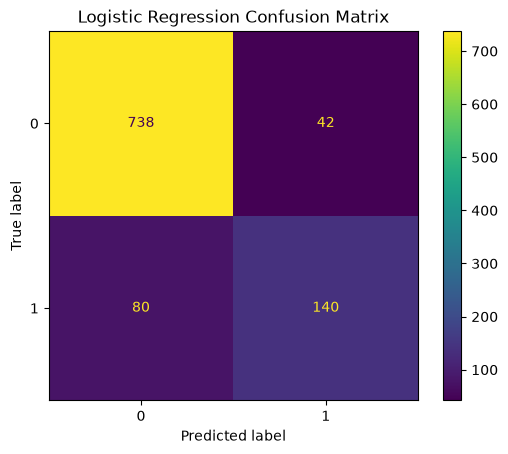

In [18]:
cm = confusion_matrix(y_test, y_pred_logistic)

ConfusionMatrixDisplay(cm).plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()

ROC-AUC: 0.9196969696969697


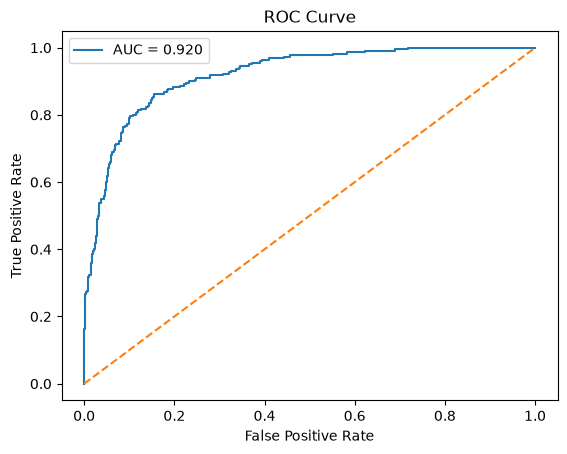

In [19]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", auc)

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [20]:
for threshold in [0.3, 0.5, 0.7]:
    y_pred = (y_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Accuracy :", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall   :", recall_score(y_test, y_pred))
    print("F1-score :", f1_score(y_test, y_pred))


Threshold: 0.3
Accuracy : 0.867
Precision: 0.6617100371747212
Recall   : 0.8090909090909091
F1-score : 0.7280163599182005

Threshold: 0.5
Accuracy : 0.878
Precision: 0.7692307692307693
Recall   : 0.6363636363636364
F1-score : 0.6965174129353234

Threshold: 0.7
Accuracy : 0.854
Precision: 0.8189655172413793
Recall   : 0.4318181818181818
F1-score : 0.5654761904761905


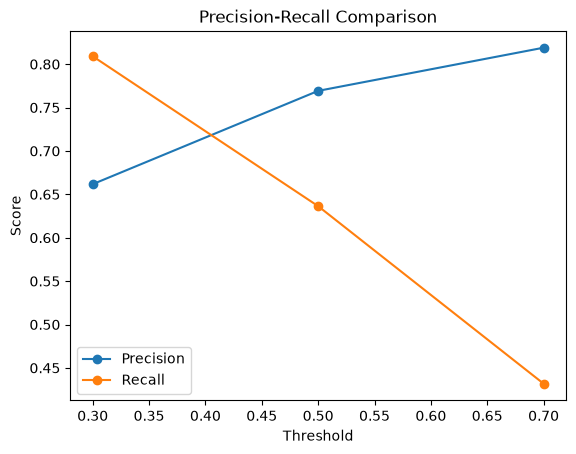

In [21]:
thresholds = [0.3, 0.5, 0.7]

precisions = []
recalls = []

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)

    precisions.append(precision_score(y_test, y_pred))
    recalls.append(recall_score(y_test, y_pred))

plt.plot(thresholds, precisions, marker="o", label="Precision")
plt.plot(thresholds, recalls, marker="o", label="Recall")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall Comparison")
plt.legend()
plt.show()